# Two-tower recommender (PyTorch)

All logic lives in `src/` (unit-tested in CI); this notebook only *calls* it.
The design choices that matter:

- **Temporal split** (80/10/10 by review date) - never a random row split.
- **As-of features** - every user/item feature uses only reviews strictly *earlier* than the row it describes; anything fitted (TF-IDF, SVD, scalers, vocabularies) sees train rows only.
- **Bias head** - `y_hat = mu + b_user + b_item + <tower_u, tower_i>`; unseen ids fall back to a zero bias (slot 0).
- **Honest baselines** - mean, item/user mean, user+item bias, an as-of version, and item-kNN.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # run from the repo root so config paths resolve

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.benchmark import run_benchmark, write_results
from src.config import load_config
from src.data import load_interactions
from src.features.item import build_item_static
from src.models.two_tower import load_model, save_model
from src.pipeline import load_or_build_features
from src.ranking import catalog_embeddings
from src.seed import resolve_device
from src.similarity import most_similar_items
from src.split import assert_no_leakage, split_report, temporal_split
from src.train import train_model

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
cfg = load_config()
RUN_DIR = Path("runs/notebook")

## 1. Data and the temporal split

In [2]:
interactions = load_interactions(cfg.data.dir, cfg.data.cache_dir)
labels, cutoffs = temporal_split(interactions, cfg.split.val_frac, cfg.split.test_frac)
assert_no_leakage(interactions, labels)  # raises if the future leaks into the past, or a (user, product) pair spans splits

print(f"{len(interactions):,} interactions | {interactions.author_id.nunique():,} users | {interactions.product_id.nunique():,} products")
print(f"val starts {cutoffs.val_start.date()} | test starts {cutoffs.test_start.date()}")
split_report(interactions, labels)

1,088,824 interactions | 503,195 users | 2,351 products
val starts 2022-02-02 | test starts 2022-08-16


,rows,frac,start,end,cold_user,cold_item,mean_rating
split,,,,,,,
train,870476,0.799464,2008-08-28,2022-02-01,0.000000,0.000000,4.290489
val,109438,0.100510,2022-02-02,2022-08-15,0.492133,0.383130,4.322073
test,108910,0.100025,2022-08-16,2023-03-21,0.553402,0.443917,4.332550


`cold_user` / `cold_item` = share of a split's rows whose user / product has **no train review**. Roughly half of the test period is cold on one side or the other, which a random split would hide entirely - and is why the bias terms fall back to zero and the towers carry the content signal.

## 2. Leak-free features

In [3]:
fs = load_or_build_features(cfg)  # cached after the first call; fit on train rows only
print("user features:", fs.X_user.shape[1], "| item features:", fs.X_item.shape[1], "| train mean rating:", round(fs.mu, 4))
print("snapshot catalog columns (rating, reviews, loves_count, out_of_stock) used?",
      any(n in fs.artifacts["item_tf"].feature_names_ for n in ["rating", "reviews", "loves_count", "out_of_stock"]))
pd.Series(fs.artifacts["item_tf"].feature_names_[:14], name="first item features").to_frame()

user features: 103 | item features: 23 | train mean rating: 4.2905
snapshot catalog columns (rating, reviews, loves_count, out_of_stock) used? False


,first item features
0,i_hist_count
1,i_rating_mean
2,price_usd
3,child_count
4,child_max_price
5,child_min_price
6,size_ml
7,brand_freq
8,size_ml__missing
9,price_usd__missing


## 3. Train

In [4]:
device = resolve_device(cfg.train.device)
result = train_model(fs, cfg, device=device)
RUN_DIR.mkdir(parents=True, exist_ok=True)
save_model(result.model, RUN_DIR / "model.pt")
print(f"best epoch {result.best_epoch}, val RMSE {result.best_val_rmse:.4f}")

epoch  1  train_loss 1.2374  val_rmse 1.0479  val_mae 0.7598


epoch  2  train_loss 1.2006  val_rmse 1.0454  val_mae 0.7768


epoch  3  train_loss 1.1712  val_rmse 1.0456  val_mae 0.7519


epoch  4  train_loss 1.1467  val_rmse 1.0480  val_mae 0.7584


epoch  5  train_loss 1.1252  val_rmse 1.0480  val_mae 0.7572
early stop at epoch 5 (best 2, val_rmse 1.0454)
best epoch 2, val RMSE 1.0454


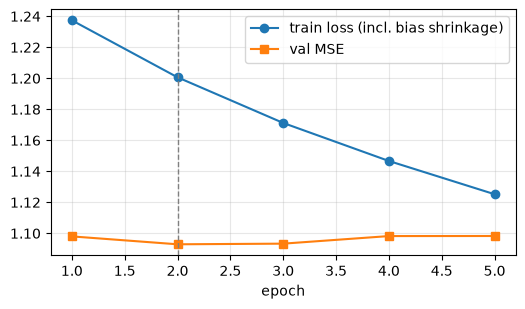

In [5]:
hist = pd.DataFrame(result.history)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(hist.epoch, hist.train_loss, marker="o", label="train loss (incl. bias shrinkage)")
ax.plot(hist.epoch, hist.val_rmse ** 2, marker="s", label="val MSE")
ax.axvline(result.best_epoch, color="grey", ls="--", lw=1)
ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 4. Baselines vs the two-tower

Baseline shrinkage strengths are tuned on **val only**; the test split is scored once per run. `user+item as-of` is the fair counterpart to the neural model: it sees exactly the same strictly-earlier history.

In [6]:
results = run_benchmark(cfg, fs, result.model)
write_results(results, RUN_DIR)
results["rating"]["test"].sort_values("rmse").round(4)

  tuned on val: k=100 (rmse 1.1111)


  tuned on val: k=5 (rmse 1.0873)


  tuned on val: lu=5,li=25 (rmse 1.0779)


  tuned on val: as-of additive k_user,k_item=(5, 25)


  tuned on val: sim_shrink=10,den=0.3 (rmse 1.1189)


,rmse,mae,rmse [no history],rmse [1 prior],rmse [2-4 prior],rmse [5+ prior]
two-tower (PyTorch),1.0260,0.7426,1.2735,1.0730,1.0136,0.6781
user+item as-of,1.0424,0.6955,1.2957,1.0897,1.0297,0.6856
user+item bias,1.0776,0.8093,1.3040,1.1224,1.0734,0.7690
user mean,1.0795,0.8073,1.3191,1.1237,1.0698,0.7518
item mean,1.1040,0.8571,1.3060,1.1363,1.0896,0.8479
item kNN (k=40),1.1078,0.8571,1.3074,1.1418,1.0971,0.8529
global mean,1.1116,0.8717,1.3191,1.1404,1.0905,0.8524


In [7]:
results["rating"]["val"].sort_values("rmse").round(4)

,rmse,mae,rmse [no history],rmse [1 prior],rmse [2-4 prior],rmse [5+ prior]
two-tower (PyTorch),1.0454,0.7768,1.2191,1.0634,1.0115,0.7389
user+item as-of,1.0584,0.7331,1.2337,1.0723,1.0257,0.7510
user+item bias,1.0779,0.8111,1.2433,1.1008,1.0537,0.7825
user mean,1.0873,0.8129,1.2657,1.1077,1.0571,0.7687
item mean,1.1111,0.8654,1.2469,1.1188,1.0853,0.8916
item kNN (k=40),1.1189,0.8693,1.2523,1.1293,1.0978,0.8996
global mean,1.1228,0.8807,1.2657,1.1266,1.0926,0.8950


### Full-catalog ranking

For each liked held-out review, rank *every* product that existed that day (minus what the user already reviewed). A rating regressor is not trained to rank, so this is expected to be weak - the table shows by how much.

In [8]:
meta = results["ranking"]["test"]["_meta"]
print(f"{meta['n_targets']:,} liked test interactions, ~{meta['mean_candidates']:.0f} candidate products each")
pd.DataFrame({k: v for k, v in results["ranking"]["test"].items() if k != "_meta"}).T.round(4)

20,000 liked test interactions, ~2189 candidate products each


,mrr,hr@5,ndcg@5,hr@10,ndcg@10,hr@20,ndcg@20
popularity,0.0145,0.0092,0.0079,0.0192,0.0110,0.0345,0.0149
item mean rating,0.0189,0.0220,0.0121,0.0498,0.0212,0.0774,0.0282
two-tower,0.0069,0.0034,0.0021,0.0086,0.0037,0.0207,0.0067
random (expected),0.0038,0.0023,0.0013,0.0046,0.0021,0.0092,0.0032


## 5. What did the item tower learn? Nearest products

In [9]:
product_info = pd.read_csv(cfg.data.product_info)
inter = fs.meta[["author_id", "product_id", "submission_time"]].assign(rating=fs.y.astype("float64"))
ids, emb = catalog_embeddings(fs, inter, build_item_static(product_info), result.model, cfg.features.item_shrinkage)

query = pd.Series(fs.meta.product_id[fs.split == "train"]).value_counts().index[0]  # most-reviewed train product
names = product_info.set_index("product_id")[["product_name", "brand_name", "price_usd"]]
print("query:", names.loc[query].to_dict())
similar = most_similar_items(query, ids, emb, top_k=8)
similar.merge(names, left_on="product_id", right_index=True, how="left")

query: {'product_name': 'Lip Sleeping Mask Intense Hydration with Vitamin C', 'brand_name': 'LANEIGE', 'price_usd': 24.0}


,product_id,sq_distance,product_name,brand_name,price_usd
0,P442840,0.009797,Barrier+ Triple Lipid-Peptide Face Cream,Skinfix,54.0
1,P427419,0.010436,Hyaluronic Acid 2% + B5 Hydrating Serum,The Ordinary,15.7
2,P458219,0.011150,Watermelon Glow PHA + BHA Pore-Tight Toner,Glow Recipe,34.0
3,P278317,0.011844,Facial Radiance Pads,First Aid Beauty,36.0
4,P418624,0.012385,Noni Glow Plumping Face Oil,KORA Organics,72.0
5,P454380,0.012631,Unseen Sunscreen SPF 40 PA+++,Supergoop!,48.0
6,P416563,0.012986,Squalane + Vitamin C Rose Firming Oil,Biossance,74.0
7,P470529,0.013198,Avocado Soothing Skin Barrier Serum with Ceram...,Glow Recipe,45.0
